# 01 · 从 blinking 到 HMM
先阅读 `notes/01_hmm.md`。状态是 off/on，观测是每帧 photon count；off 仍有背景。参数先视为已知。
本实验：生成 → filtering → smoothing → 穷举核对 → EM 更新。


In [1]:
import sys
from pathlib import Path
root = Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0,str(root))
import numpy as np
import matplotlib.pyplot as plt
from src.hmm import forward_backward, brute_force, poisson_log_emissions
rng=np.random.default_rng(7)


log likelihood -157.79250326528387


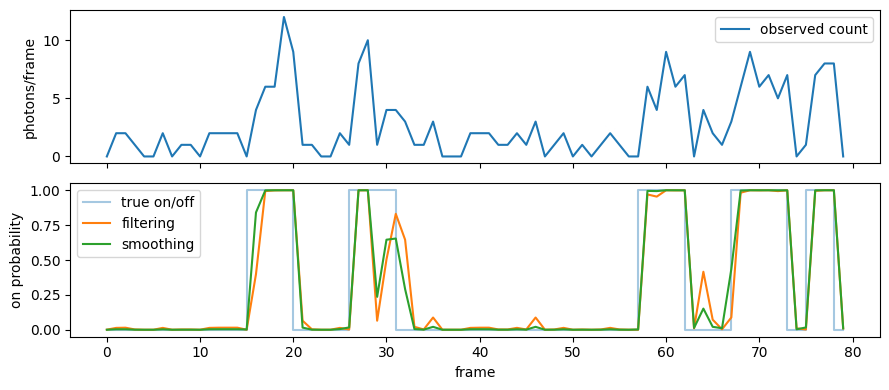

In [2]:
pi=np.array([.8,.2]); A=np.array([[.9,.1],[.2,.8]]); rates=np.array([1.,7.])
T=80; z=np.zeros(T,dtype=int); z[0]=rng.choice(2,p=pi)
for t in range(1,T): z[t]=rng.choice(2,p=A[z[t-1]])
y=rng.poisson(rates[z])
ll,gamma,xi,filt=forward_backward(poisson_log_emissions(y,rates),pi,A)
fig,ax=plt.subplots(2,1,figsize=(9,4),sharex=True)
ax[0].plot(y,label='observed count'); ax[0].set_ylabel('photons/frame'); ax[0].legend()
ax[1].step(range(T),z,label='true on/off',alpha=.4)
ax[1].plot(filt[:,1],label='filtering'); ax[1].plot(gamma[:,1],label='smoothing')
ax[1].set(xlabel='frame',ylabel='on probability'); ax[1].legend(); plt.tight_layout()
print('log likelihood',ll)


In [3]:
small=poisson_log_emissions(y[:8],rates)
a,g,*_=forward_backward(small,pi,A); b,h,*_=brute_force(small,pi,A)
assert np.allclose(a,b) and np.allclose(g,h)
print('Exact enumeration agrees.')


Exact enumeration agrees.


## EM：每一步重新推断，不用真实 z
单序列 pi 的估计较不稳定；此处只更新 A 和 rates，固定 pi。EM 保证精确 E/M 步下 likelihood 不下降，不保证找到全局最优。


Estimated A, rates: [[0.89871423 0.10128577]
 [0.24836616 0.75163384]] [1.15940677 6.81188393]


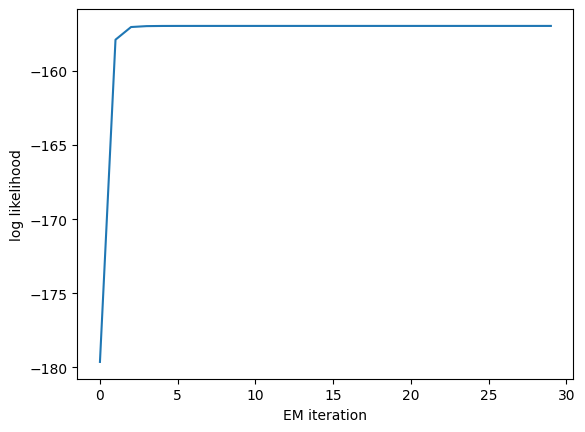

In [4]:
Ae=np.array([[.7,.3],[.3,.7]]); re=np.array([2.,5.]); history=[]
for _ in range(30):
    value,g,x,_=forward_backward(poisson_log_emissions(y,re),pi,Ae)
    history.append(value)
    counts=x.sum(axis=0)
    Ae=counts/counts.sum(axis=1,keepdims=True)
    re=(g*y[:,None]).sum(axis=0)/g.sum(axis=0)
assert np.min(np.diff(history))>=-1e-8
print('Estimated A, rates:',Ae,re)
plt.plot(history); plt.xlabel('EM iteration'); plt.ylabel('log likelihood');


## 掌握检查
1. 为什么 smoothing 能使用未来观测？
2. 将 on/off rate 拉近，后验如何变化？
3. 降低 photons 后，时间先验是否总能救回状态？
4. gamma 的逐帧 argmax 为什么不是 Viterbi path？
5. 多序列 EM 的 transition counts 如何合并？
